# **MODULE 10 — SPECTROGRAM & TIME-FREQUENCY VISUALIZATION 🎵**

**Core Speech-Processing Concept**

**Important for NLP & Audio AI**

In Module 8, we learned FFT. In Module 9, we learned STFT.

Now we're going to combine those concepts to understand one of the most important visualizations in speech processing: the **spectrogram**.

A spectrogram allows us to see how the frequency content of a sound changes over time.

Think of it this way:

- **Waveform:** What is the amplitude of the sound at each moment?
- **FFT:** Which frequencies are present in the analyzed signal?
- **STFT:** Which frequencies are present in each short-time frame?
- **Spectrogram:** A visual representation of that time-frequency information.

---

## **10.1 What Is a Spectrogram?**

A spectrogram is a visual representation of the frequency content of an audio signal over time.

It is generally produced from the Short-Time Fourier Transform (STFT).

A spectrogram has three dimensions:

1. **Time** — horizontal axis.
2. **Frequency** — vertical axis.
3. **Magnitude or power** — represented by color intensity.

![Spectrogram visualization](https://images.openai.com/static-rsc-4/JkR3aELdDPXrcXdQJUjDMrj8cEI9gk0SlCA-LWKD-Y8v5nkUjcvZxjMNk4gr6dDyM9dpPytcyeZwkMHT_6G4xhkZJfRyWQUOQTYXqwcRTk9Uir14I78ucifKJN-ZMcdd1cWTEABjW2i9D6KlKUYZ4ATIu6BhNJgF3r5rgVOgCYk?purpose=inline)

Reference: [Master Image to Spectrogram Conversion with Python — AI Video Detector](https://www.aivideodetector.com/blog/image-to-spectrogram?utm_source=chatgpt.com)

### **How to read it**

| Visual element | Meaning |
|---|---|
| X-axis | Time in seconds |
| Y-axis | Frequency in Hz |
| Bright regions | Stronger spectral components |
| Dark regions | Weaker spectral components |
| Horizontal bands | Sustained frequency components |
| Vertical patterns | Rapid changes or transient sounds |

For example, if a speaker produces a vowel, you may observe horizontal harmonic bands and stronger regions around vocal-tract resonances.

If the speaker produces an unvoiced fricative such as `/s/`, you may observe broadband high-frequency energy.

---

## **10.2 STFT to Spectrogram**

Let's connect Module 9 with this module.

The STFT produces a matrix of complex values:

$$
X(m,k)
$$

Where:

- $m$ = Time-frame index
- $k$ = Frequency-bin index

Each matrix element represents a complex frequency component at a particular time and frequency.

To visualize this matrix, we calculate its magnitude or power.

### **The basic pipeline**

**Raw audio signal**

Digital samples

↓

**Frame extraction**

Window length and hop length

↓

**Windowing + FFT**

Calculate STFT

↓

**Magnitude or power**

Convert complex values into non-negative values

↓

**Spectrogram**

The spectrogram is therefore not a separate Fourier Transform. It is a visualization of the STFT-derived information.

---

## **10.3 Magnitude Spectrogram**

The STFT produces complex numbers.

To visualize the strength of frequency components, we calculate their absolute values.

$$
M(m,k)=|X(m,k)|
$$

Where:

- $X(m,k)$ = Complex STFT value
- $M(m,k)$ = Magnitude spectrogram

### **Python implementation**

```python
magnitude_spectrogram = np.abs(Zxx)
```

### **What does magnitude tell us?**

It shows how strong each frequency component is at each point in time.

For example:

- A strong harmonic may appear as a bright horizontal band.
- A weak frequency component may appear darker.
- Silence may appear as a region with very low magnitude.

![Harmonic spectrum](https://images.openai.com/static-rsc-4/uxyeSQGAa37N0LoYtNa734h08hgpTXorHIOrEc0s6hD_pwxN9xnBi3SdIpl90m2Cym5-ty_WwtwLS9rrV76LPFNHuNmdnc-y2VvGyeQg2MR3ZvZwsocfJMPxgc2UFappkXQS05gHeJKoySESN8uL2TvaEcaRKjhX8x2W3waw3VI?purpose=inline)

Reference: [Harmonic Spectrum — librosa Documentation](https://librosa.org/doc/0.10.2/auto_examples/plot_spectral_harmonics.html?utm_source=chatgpt.com)

---

## **10.4 Power Spectrogram**

Instead of using magnitude, we can use squared magnitude.

$$
P(m,k)=|X(m,k)|^2
$$

### **Python implementation**

```python
power_spectrogram = np.abs(Zxx) ** 2
```

Power emphasizes stronger components more strongly because the magnitude is squared.

| Magnitude spectrogram | Power spectrogram |
|---|---|
| $|X(m,k)|$ | $|X(m,k)|^2$ |
| Magnitude representation | Squared-magnitude representation |
| Useful for general visualization | Useful for power-based analysis |

**Important:** These are raw magnitude and power values unless the STFT has been appropriately normalized. A power spectrogram is not automatically a calibrated physical power measurement.

---

## **10.5 Log Spectrogram**

Real-world audio often has frequency components with very different magnitudes.

For example, a recording might contain:

- Strong vowel harmonics.
- Weak background noise.
- Low-energy consonant components.
- Strong low-frequency components.

When we plot raw magnitudes, weaker components can become difficult to see.

To improve visualization, we often use a logarithmic scale.

A log-magnitude representation can be calculated as:

$$
L(m,k)=\log_{10}(|X(m,k)|+\epsilon)
$$

Where $\epsilon$ is a small positive number to avoid taking the logarithm of zero.

### **Python implementation**

```python
log_spectrogram = np.log10(
    magnitude_spectrogram + 1e-10
)
```

This compresses the dynamic range.

Weak components become easier to observe relative to stronger ones.

---

## **10.6 Decibel Scaling**

Another common approach is converting magnitude or power into decibels (dB).

### **Magnitude to dB**

$$
M_{dB}=20\log_{10}
\left(
\frac{M}{M_{\text{ref}}}
\right)
$$

### **Power to dB**

$$
P_{dB}=10\log_{10}
\left(
\frac{P}{P_{\text{ref}}}
\right)
$$

Here, $M_{\text{ref}}$ and $P_{\text{ref}}$ are reference values.

For a relative display, we often use the maximum value as the reference:

### **Python implementation**

```python
magnitude_db = 20 * np.log10(
    magnitude_spectrogram /
    (magnitude_spectrogram.max() + 1e-10)
    + 1e-10
)
```

This makes the maximum approximately 0 dB and weaker components negative.

### **Why use decibels?**

- Compresses large dynamic ranges.
- Makes weaker components easier to visualize.
- Helps compare spectral patterns.
- Is widely used in audio and speech-processing applications.

![Logarithmic spectrogram visualization](https://images.openai.com/static-rsc-4/3Fs1eLix2KZqJYn-9p57rEfREK6KU9PpmC6X092SPq9LiQv8Cwlpz2QlDN-KbCSDECL4rXPgK8cAqonS3OcI25hpo6tV0d9-gF_q_p1oW3rY4TDCGbBxoe8ySFB5dVe-qpy-RM-L2vwxpbi53KCmAEO376o-nPgX7dZzRP7QPK4?purpose=inline)

Reference: [librosa.display.specshow — librosa Documentation](https://librosa.org/doc/latest/generated/librosa.display.specshow.html?utm_source=chatgpt.com)

**Remember:** A 20-log formula is used for amplitude or magnitude ratios; a 10-log formula is used for power ratios.

---

## **10.7 Time Axis, Frequency Axis and Color Intensity**

Let's understand the three dimensions more carefully.

![Spectrogram dimensions](https://images.openai.com/static-rsc-4/d3OUNQWFUicSgylWh6Pdy6lc753bpatOmnGFrYqtFC8jUtyKFU9ms0Gf9ACtCXFgWNyihwBxhOCWq61nJie5tq-wnGFqoAtOz6bNNPjQfTJ2K17PrPOqIxylaCuXBTSNNr5lKFKTHbENwpjhL95yPnUD1yprUrHNp6BlzGK8C2g?purpose=inline)

Reference: [What Is a Spectrogram? — MALMIJAL-M Blog](https://mmjal.com/BLOG/?bmode=view&idx=170257146&utm_source=chatgpt.com)

### **A. Time axis — X-axis**

The horizontal axis represents time.

It tells us when a particular frequency component appears.

For example:

- 0.0–0.2 seconds: Silence
- 0.2–0.5 seconds: Vowel
- 0.5–0.8 seconds: Consonant

The exact time values depend on the recording and the STFT frame settings.

### **B. Frequency axis — Y-axis**

The vertical axis represents frequency in Hz.

Different frequency regions can contain different speech characteristics.

| Frequency region | Possible speech information |
|---|---|
| Lower frequencies | Fundamental frequency and lower harmonics |
| Middle frequencies | Important vowel formant structures |
| Higher frequencies | Higher formants and consonant noise, depending on the sound |

These are broad tendencies, not fixed frequency boundaries. Speech characteristics overlap across frequency regions.

### **C. Color intensity**

Color represents the strength of a frequency component.

For example:

- Bright yellow or white: Stronger component.
- Orange: Moderate component.
- Purple or dark: Weaker component.

The exact colors depend on the selected colormap and the scale being displayed.

**Important:** A spectrogram's color does not directly represent pitch, loudness or emotion. It represents the chosen spectral quantity, such as magnitude or power.

---

## **10.8 Reading Spectrograms**

Now let's learn how to interpret actual speech patterns.

### **1. Vowels**

Examples:

- `/a/` as in "father"
- `/i/` as in "see"
- `/u/` as in "food"

Vowels are generally produced with a relatively open vocal tract and voiced vocal-fold vibration.

In a spectrogram, voiced vowels often show:

- Horizontal harmonic bands.
- Strong energy at certain frequency regions.
- Formant structures.
- Relatively sustained patterns over time.

![Adult female vowels](https://images.openai.com/static-rsc-4/pa_xJLMqKuAir6dekgtLI-qXX6QnL9v8x6uzvFqI_v8U1S_jQ79JJFsr6YauPM_ikoPiRBwhoFPgDI-Cv62oHfT-eFqncv7txXk7RsSxsuEUO3psjpTEkMmLDIFvvc2JTL9agtjhgqsCoxkD3QlBETlhLqEu6slgYg5NZwtQ7_M?purpose=inline)

Reference: [Adult Female Vowels — University of Texas at Dallas](https://www.utdallas.edu/~assmann/KIDVOW/adfem.html?utm_source=chatgpt.com)

### **2. Consonants**

Consonants have different acoustic patterns depending on their manner and place of articulation.

Examples:

| Consonant | Acoustic characteristic |
|---|---|
| `/s/` | Strong high-frequency frication |
| `/f/` | Often weaker, diffuse frication |
| `/m/` | Voiced nasal sound |
| `/t/` | Short closure followed by a burst |
| `/h/` | Noise-like sound shaped by the following vowel |

![Phonetics and spectrograms](https://images.openai.com/static-rsc-4/OobPN701_8c8c6acthR2o3A6jZ40QMUFRBChJXQi3WU7guKR17umlrK2jaTBQTSNj2_LEpxvRUMQDTnaElIBItk7FFUgDbYxlyEhqoJ-MT0H9LjNoci8TMKJH0sM3N3Cxig-GUqrKQWUvbS4zpfzH7P-0ry3nX1u9IyL4KkKWYo?purpose=inline)

Reference: [Phonetics and Spectrograms — dummies](https://www.dummies.com/article/academics-the-arts/language-language-arts/linguistics/phonetics/phonetics-and-spectrograms-putting-sounds-on-paper-163428/?utm_source=chatgpt.com)

Notice that not all consonants look alike. Some are voiced, some unvoiced, some nasal, and some involve short bursts.

### **3. Voiced and unvoiced regions**

This connects directly to Module 3, where we studied vocal-fold vibration.

**Voiced sounds**

- Vocal folds vibrate.
- Usually have a periodic or approximately periodic structure.
- Often show harmonic bands in a spectrogram.
- Examples: Vowels, `/m/`, `/n/`, `/z/`.

**Unvoiced sounds**

- Do not have regular vocal-fold vibration during the unvoiced portion.
- Often have noise-like spectral structures.
- May show broadband or high-frequency energy.
- Examples: `/s/`, `/f/`, `/ʃ/`.

![Voiced speech](https://images.openai.com/static-rsc-4/-OYJZwN8qLsU1-uGzwuZJsMIZWt6qs3QHPO4AqPJ3c11Ws7XYcyodUBH26L_ar23HHh8WvDUxWiMGcy05xx5GYlAYRTUTvtDRKxv8RlY2EYwLkayoFMV0496Si4EqyTWqLH6Q9uSRzF1wOwYu0gCaur-SXcCND4ef-l0esuxBvM?purpose=inline)

**Voiced**

Regular harmonic structure

![Unvoiced speech](https://images.openai.com/static-rsc-4/tpgErhpVvrs-yEFRk8Xvsw9fWvosfEwcx-6mgYVmNxU7ryR7KE_LIjHDZsIEGgCaUD94TfQr0uLBIBPKysE8ptaugxE7LLa6H70GhoH5tFO93_lakIF1V3vMXfMubiq4OskqpPaQGLTonIhGsYbCFFzaxCjOs6j6Atuawb5CIck?purpose=inline)

**Unvoiced**

Noise-like energy distribution

A useful caution: unvoiced does not mean silent. An `/s/` sound can contain substantial acoustic energy without vocal-fold vibration.

## **10.9 Formant Structures**

This is particularly important for understanding vowel sounds.

Recall the source-filter theory from Module 3:

- Vocal folds produce the excitation.
- The vocal tract acts as a resonant filter.
- The resonances of the vocal tract are called **formants**.

The first three formants are commonly represented as:

- $F_1$
- $F_2$
- $F_3$

![Spectrogram showing vowel formants](https://images.openai.com/static-rsc-4/FdCHMakJ__xkSFw_o-E6e51tcoYcl-HJpTPfSAkqcW46wsoNCl9mDq2YSUbNlEkUpQxXHM5Jf2olmLOKnYV--5Q-85Q44G5yDLxHaZrv7dMhuDbG2ePVSjdflrrBrSZ-lm4k78YKUtI7iXoLs7VO2XfpVc0yq7LtqfxetXHgDeo?purpose=inline)

Reference: [Spectrogram of the Vowels /i/, /ɑ/, and /u/ — ResearchGate](https://www.researchgate.net/figure/Spectrogram-of-the-vowels-i-and-u-showing-the-first-three-formants-F1-F2-and_fig1_243126231?utm_source=chatgpt.com)

### **What do formants tell us?**

| Formant | General relationship |
|---|---|
| F1 | Related strongly to vowel height / tongue openness |
| F2 | Related strongly to tongue frontness or backness |
| F3 | Contributes additional vocal-tract information |

A useful general rule:

- Higher F1 often corresponds to a more open vowel.
- Higher F2 often corresponds to a more front vowel.

For example, the vowels `/i/` and `/u/` tend to have very different F1 and F2 patterns.

**Do not confuse formants with harmonics:**

- Harmonics are multiples of the fundamental frequency.
- Formants are resonances of the vocal tract that shape the spectral envelope.

The formant frequencies are not necessarily located exactly on individual harmonic peaks.

---

## **10.10 Speech Transitions**

Speech is not produced as isolated blocks of perfectly separated sounds.

When we move from one phoneme to another, the vocal tract changes its shape continuously.

This creates **speech transitions**.

For example, when saying a word such as "cat":

- The articulators prepare for the `/k/` sound.
- A closure and release occur.
- The vowel `/æ/` follows.
- The articulators move toward `/t/`.

In the spectrogram, you may observe:

- Changes in formant positions.
- Short bursts.
- Changes in harmonic structure.
- Changes in spectral energy.

![Speech transitions](https://images.openai.com/static-rsc-4/RNjtmheIFZwuS2sedeS7MpbIPN_Jo4OV0OMlx6rhYTvjAAtd4N4H0bqFh-XcecIqx0toOSlszJlO8TM_vAjLfHiwNJc1DoUY1jt2Iz4O9YK1Q_O_prEgsw_JWuYPQGE0dai52iIcAI_xYaDwx6hODVkhjDLEytkQyeUOD4k9Fbc?purpose=inline)

Reference: [Singer Timing Is Wrong — Dreamtonics Forum](https://forum.dreamtonics.com/t/singer-timing-is-wrong/402?utm_source=chatgpt.com)

These transitions are important because speech recognition systems must interpret sounds that are continuously changing, not just isolated steady-state vowels.

---

### **How to identify the regions**

| Observation | Likely interpretation |
|---|---|
| Clear horizontal harmonic bands | Voiced vowel |
| Strong diffuse high-frequency energy | Unvoiced `/s/` |
| Very low energy throughout | Silence |
| Changes in formant positions | Speech transition |

You can also use short-time RMS and zero-crossing rate as supporting measurements. However, neither is a perfect voiced/unvoiced detector on its own.

---

## **10.17 Important Concepts — Final Revision**

| Concept | What you should remember |
|---|---|
| Spectrogram | Visual representation of frequency content over time |
| Magnitude spectrogram | Absolute magnitude of STFT |
| Power spectrogram | Squared magnitude of STFT |
| Log spectrogram | Logarithmic representation of spectral values |
| Decibel scaling | Compresses dynamic range |
| Formants | Vocal-tract resonances |
| Harmonics | Integer multiples of fundamental frequency |
| Voiced sounds | Usually exhibit harmonic structure |
| Unvoiced sounds | Often exhibit noise-like energy |
| Speech transitions | Changes in acoustic patterns between phonemes |

---

## **What You Should Remember**

1. A spectrogram is a visualization of time-frequency information obtained from STFT.
2. The X-axis represents time, Y-axis represents frequency, and color represents magnitude or power.
3. Vowels commonly show harmonic structures and formant regions.
4. Unvoiced fricatives commonly show noise-like spectral energy.
5. Formants describe vocal-tract resonances, while harmonics relate to fundamental frequency.
6. Spectrograms help us study speech transitions and changing acoustic patterns.
7. Magnitude, power and decibel representations are different ways of displaying spectral information.

---

## **Interview Questions**

1. What is a spectrogram?
2. How is a spectrogram generated from STFT?
3. What is the difference between magnitude and power spectrograms?
4. Why do we use logarithmic scaling?
5. What do the three dimensions of a spectrogram represent?
6. How can you distinguish voiced and unvoiced speech in a spectrogram?
7. What are formants, and how are they different from harmonics?
8. How do vowel and fricative spectrograms differ?
9. What are speech transitions?
10. Why are spectrograms useful in speech recognition?

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from scipy.signal import stft

In [2]:
fs = 16000
duration = 2

t = np.arange(0, duration, 1/fs)

signal = np.zeros_like(t)

# First second: 200 Hz
mask1 = t < 1

signal[mask1] = np.sin(
    2 * np.pi * 200 * t[mask1]
)

# Second second: 600 Hz
mask2 = t >= 1

signal[mask2] = np.sin(
    2 * np.pi * 600 * t[mask2]
)

In [3]:
frequencies, times, Zxx = stft(
    signal,
    fs=fs,
    window="hann",
    nperseg=400,
    noverlap=240,
    nfft=512,
    boundary=None,
    padded=False
)

magnitude = np.abs(Zxx)

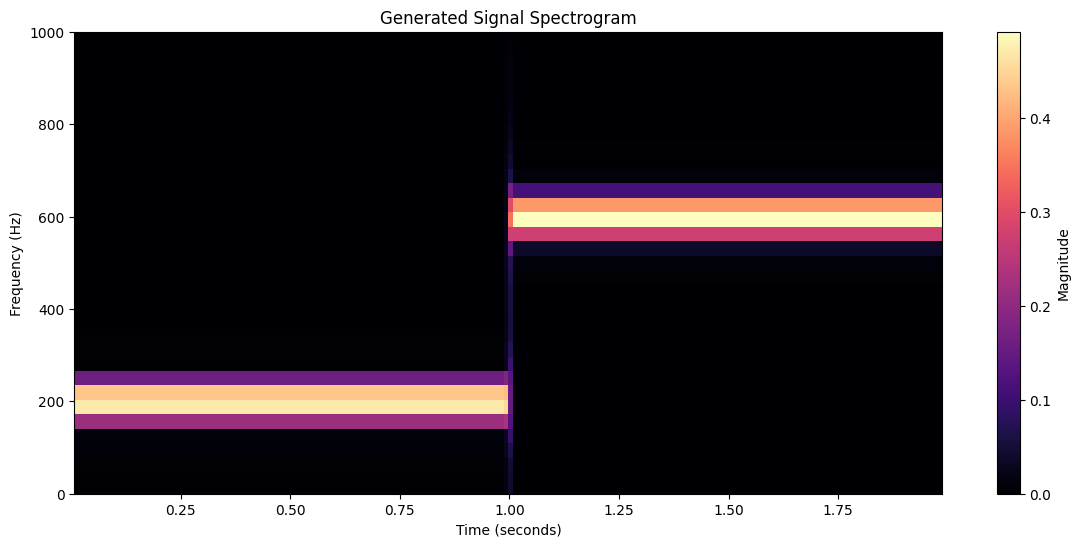

In [4]:
plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    magnitude,
    shading="auto",
    cmap="magma"
)

plt.title("Generated Signal Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, 1000)

plt.colorbar(label="Magnitude")

plt.show()

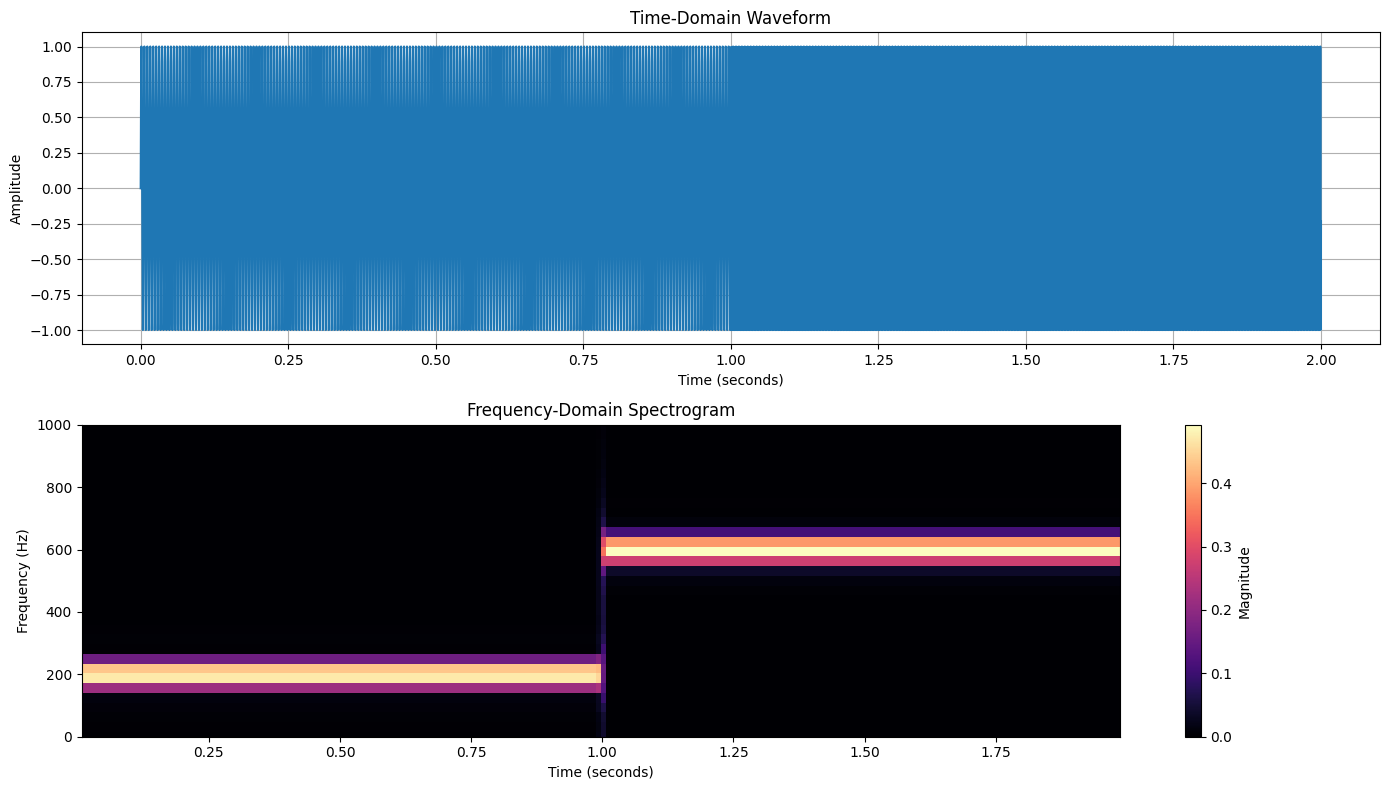

In [5]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8)
)

# Waveform
axes[0].plot(t, signal)

axes[0].set_title("Time-Domain Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

# Spectrogram
im = axes[1].pcolormesh(
    times,
    frequencies,
    magnitude,
    shading="auto",
    cmap="magma"
)

axes[1].set_title("Frequency-Domain Spectrogram")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_ylim(0, 1000)

fig.colorbar(
    im,
    ax=axes[1],
    label="Magnitude"
)

plt.tight_layout()
plt.show()

In [6]:
# Visualize a Vowel

audio, fs = sf.read("audio/raw/01_vowel_ah.wav")

if audio.ndim == 2:
    audio = audio.mean(axis=1)

print("Sampling rate:", fs)
print("Duration:", len(audio) / fs)

Sampling rate: 22050
Duration: 1.5


In [7]:
from IPython.display import Audio, display
display(Audio(audio, rate=fs))

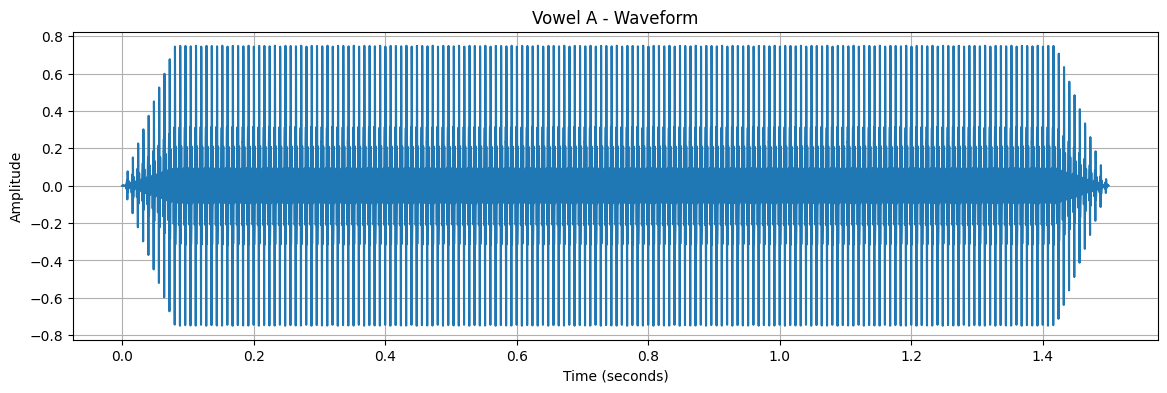

In [8]:
time = np.arange(len(audio)) / fs

plt.figure(figsize=(14, 4))

plt.plot(time, audio)

plt.title("Vowel A - Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

In [9]:
frequencies, times, Zxx = stft(
    audio,
    fs=fs,
    window="hann",
    nperseg=400,
    noverlap=240,
    nfft=512,
    boundary=None,
    padded=False
)

In [10]:
magnitude = np.abs(Zxx)

magnitude_db = 20 * np.log10(
    magnitude / (magnitude.max() + 1e-10)
    + 1e-10
)

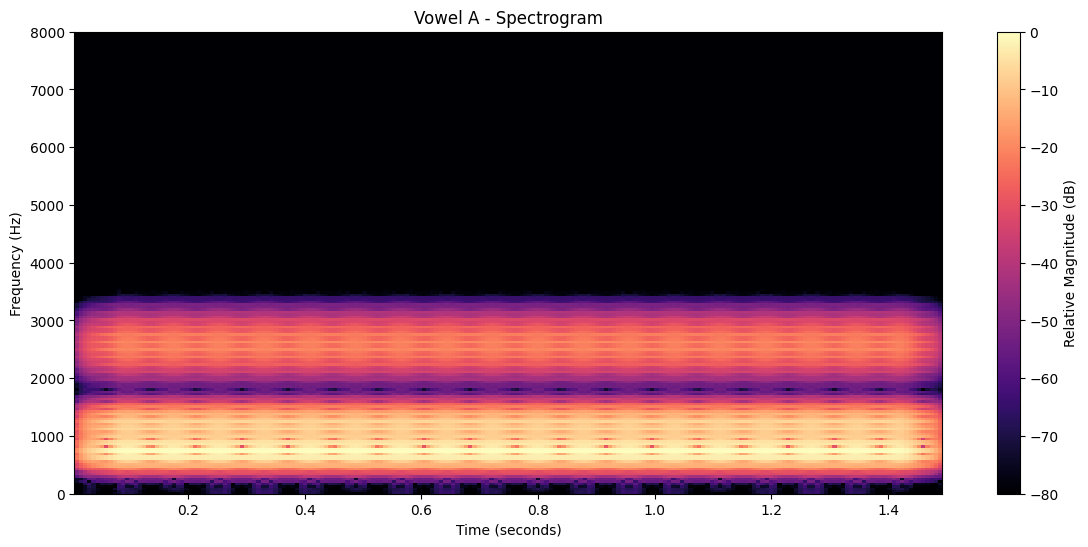

In [11]:
plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times,
    frequencies,
    magnitude_db,
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.title("Vowel A - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, min(8000, fs/2))

plt.colorbar(label="Relative Magnitude (dB)")

plt.show()

In [12]:
# Visualize a Consonant

audio_s, fs_s = sf.read("audio/raw/02_consonant_s.wav")

if audio_s.ndim == 2:
    audio_s = audio_s.mean(axis=1)

In [15]:
display(Audio(audio_s,rate=fs_s))

In [16]:
frequencies_s, times_s, Zxx_s = stft(
    audio_s,
    fs=fs_s,
    window="hann",
    nperseg=400,
    noverlap=240,
    nfft=512,
    boundary=None,
    padded=False
)

magnitude_s = np.abs(Zxx_s)

magnitude_s_db = 20 * np.log10(
    magnitude_s / (magnitude_s.max() + 1e-10)
    + 1e-10
)

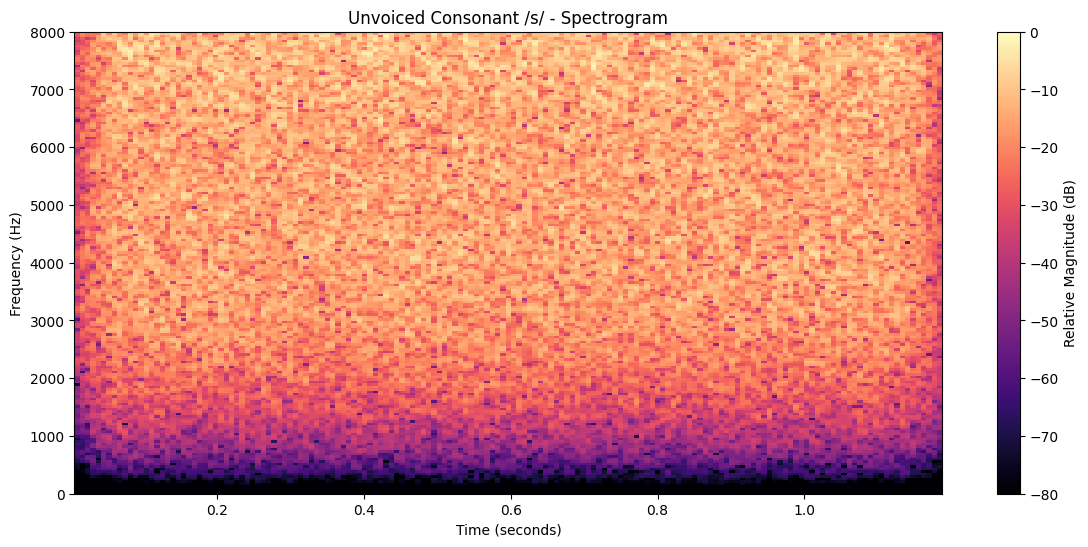

In [17]:
plt.figure(figsize=(14, 6))

plt.pcolormesh(
    times_s,
    frequencies_s,
    magnitude_s_db,
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.title("Unvoiced Consonant /s/ - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.ylim(0, min(8000, fs_s/2))

plt.colorbar(label="Relative Magnitude (dB)")

plt.show()

In [18]:
# Identify Voiced and Unvoiced Regions

audio, fs = sf.read("audio/raw/03_voiced_then_unvoiced.wav")

if audio.ndim == 2:
    audio = audio.mean(axis=1)

In [19]:
time = np.arange(len(audio)) / fs

In [20]:
display(Audio(audio,rate=fs))

In [21]:
frequencies, times, Zxx = stft(
    audio,
    fs=fs,
    window="hann",
    nperseg=400,
    noverlap=240,
    nfft=512,
    boundary=None,
    padded=False
)

magnitude = np.abs(Zxx)

magnitude_db = 20 * np.log10(
    magnitude / (magnitude.max() + 1e-10)
    + 1e-10
)

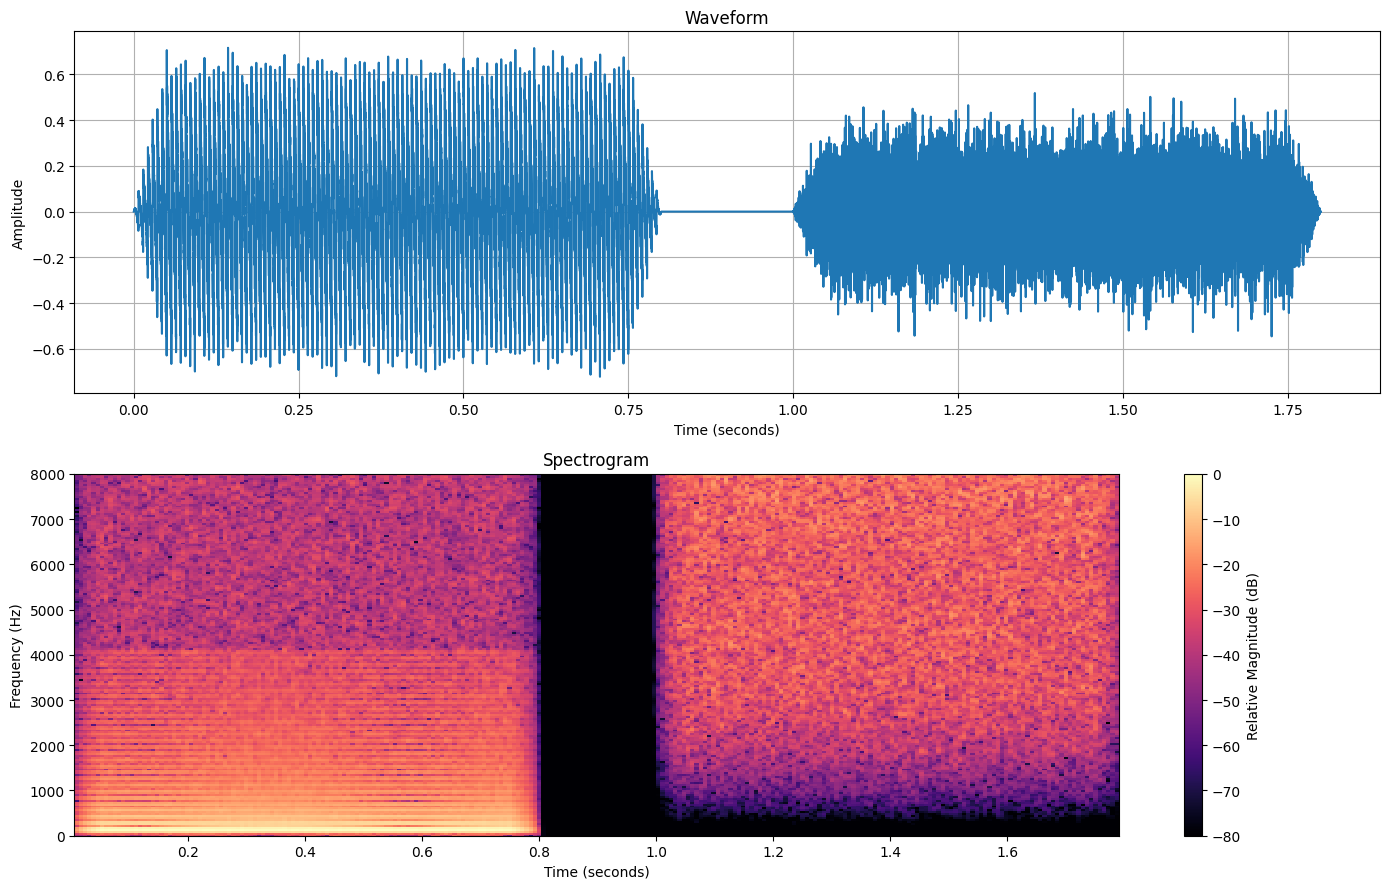

In [22]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9)
)

# Waveform
axes[0].plot(time, audio)

axes[0].set_title("Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

# Spectrogram
im = axes[1].pcolormesh(
    times,
    frequencies,
    magnitude_db,
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=0
)

axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")

axes[1].set_ylim(0, min(8000, fs/2))

fig.colorbar(
    im,
    ax=axes[1],
    label="Relative Magnitude (dB)"
)

plt.tight_layout()
plt.show()